# Regresión lineal en Python · Demostración

**Pandas → scikit-learn → evaluación → gráficos**

**Problema:** estimar el salario a partir de los años de experiencia.

**Dataset:** `Salary_Data.csv` — 30 personas, dos columnas. [Dataset original en Kaggle](https://www.kaggle.com/datasets/krishnaraj30/salary-prediction-data-simple-linear-regression).

Colocar `Salary_Data.csv` junto a este notebook y ejecutar las celdas **de arriba hacia abajo**.


## 1. Explorar el archivo

`read_csv()` abre la tabla. `head()` enseña las primeras filas, `shape` indica sus dimensiones, `isna().sum()` busca datos faltantes y `describe()` resume sus valores. Antes de entrenar, comprobar que las columnas contienen la información esperada.


In [1]:
import pandas as pd

# Carga y revisi?n inicial de los datos.
datos = pd.read_csv("Salary_Data.csv")

print("Filas y columnas:", datos.shape)
display(datos.head())

print("Valores faltantes:")
print(datos.isna().sum())

display(datos.describe())

Filas y columnas: (30, 2)


,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


Valores faltantes:
YearsExperience    0
Salary             0
dtype: int64


,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


## 2. Elegir entradas `X` y objetivo `y`

Cada fila es una persona. **`X` contiene los datos disponibles para realizar la predicción**; **`y` contiene el valor real que se quiere estimar**.

| Fila | `X`: YearsExperience (años) | `y`: Salary |
|---:|---:|---:|
| 0 | 1.1 | 39 343 |
| 1 | 1.3 | 46 205 |
| 2 | 1.5 | 37 731 |

La selección `datos[["YearsExperience"]]` produce una **tabla de entradas** con 30 filas y una columna. `datos["Salary"]` produce una **serie de objetivos** con 30 valores. Los dobles corchetes de `X` son importantes porque `scikit-learn` espera una tabla de características.

Con varias características, `X` puede tener dos o más columnas (por ejemplo `[["total_bill", "size"]]` en el dataset de propinas). La regresión sigue prediciendo **un solo `y`**, pero combina todas las columnas de `X`.


In [2]:
# Separa la caracter?stica de la variable objetivo.
X = datos[["YearsExperience"]]
y = datos["Salary"]

print("Forma de X:", X.shape, "| Forma de y:", y.shape)
display(pd.DataFrame({
    "X: experiencia (a?os)": X["YearsExperience"],
    "y: salario": y,
}).head())

Forma de X: (30, 1) | Forma de y: (30,)


,X · experiencia (años),y · salario
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


## 3. Separar datos para entrenar y evaluar

`train_test_split()` divide **las mismas filas** en dos grupos sin perder la correspondencia entre experiencia y salario:

| Conjunto | Entrada | Salario real | Para qué se usa |
|:--|:--|:--|:--|
| **Entrenamiento** (75 %) | `X_train` | `y_train` | Ajustar el modelo con `fit()`. |
| **Prueba** (25 %) | `X_test` | `y_test` | Comprobar predicciones de personas no utilizadas para entrenar. |

Las dos tablas que aparecen debajo permiten identificar qué filas quedaron en cada grupo. Los índices conservan el número original del registro. `random_state=42` hace reproducible la división.


In [3]:
from sklearn.model_selection import train_test_split

# Divide los datos sin perder la correspondencia entre X e y.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
)

print(f"Entrenamiento: {len(X_train)} filas | Prueba: {len(X_test)} filas")

print("ENTRENAMIENTO: X_train + y_train")
display(pd.DataFrame({
    "X_train: a?os": X_train["YearsExperience"],
    "y_train: salario": y_train,
}).head())

print("PRUEBA: X_test + y_test")
display(pd.DataFrame({
    "X_test: a?os": X_test["YearsExperience"],
    "y_test: salario": y_test,
}).head())

Entrenamiento: 22 filas | Prueba: 8 filas
ENTRENAMIENTO: X_train + y_train


,X_train · años,y_train · salario
12,4.0,56957.0
0,1.1,39343.0
4,2.2,39891.0
16,5.1,66029.0
5,2.9,56642.0


PRUEBA: X_test + y_test


,X_test · años,y_test · salario
27,9.6,112635.0
15,4.9,67938.0
23,8.2,113812.0
17,5.3,83088.0
8,3.2,64445.0


## 4. Entrenar y predecir

`LinearRegression()` crea el modelo. `fit(X_train, y_train)` calcula la relación entre experiencia y salario. `predict(X_test)` estima los salarios de prueba.

`coef_` es el cambio estimado del salario por un año adicional de experiencia; `intercept_` es el valor de la recta cuando la experiencia vale cero. **`y_test` no es una predicción:** son los salarios reales con los que se compara `pred`.


In [4]:
from sklearn.linear_model import LinearRegression

# Entrena el modelo y genera predicciones para el conjunto de prueba.
modelo = LinearRegression()
modelo.fit(X_train, y_train)
pred = modelo.predict(X_test)

print(f"Pendiente: {modelo.coef_[0]:,.2f}")
print(f"Intercepto: {modelo.intercept_:,.2f}")
display(pd.DataFrame({
    "Real": y_test.to_numpy(),
    "Predicho": pred,
}).head())

Pendiente: 9,371.02
Intercepto: 25,478.13


,Real,Predicho
0,112635.0,115439.881801
1,67938.0,71396.106227
2,113812.0,102320.459290
3,83088.0,75144.512658
4,64445.0,55465.378891


## 5. Visualizar los resultados

`scatter()` representa los salarios reales como puntos y `plot()` dibuja la recta que genera el modelo. Esta primera celda de gráficos establece la fuente **Palatino** en tamaño **10**, con gráficos **en blanco y negro y líneas finas** para todas las figuras siguientes (o una alternativa serif si Palatino no está instalada).


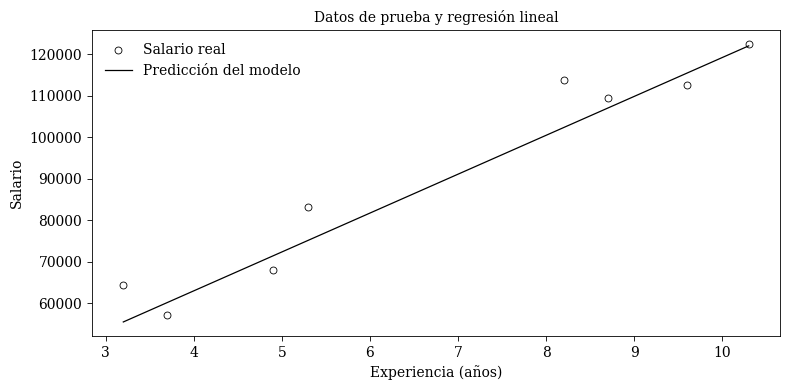

In [ ]:
import matplotlib.pyplot as plt

# Define un estilo com?n para todas las figuras.
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Palatino Linotype",
        "Palatino",
        "Book Antiqua",
        "TeX Gyre Pagella",
        "DejaVu Serif",
    ],
    "font.size": 10,
    "axes.titlesize": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "black",
    "axes.labelcolor": "black",
    "text.color": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "lines.linewidth": 0.9,
    "patch.linewidth": 0.6,
    "hatch.linewidth": 0.45,
    "axes.grid": False,
})

# Ordena los valores para dibujar la recta correctamente.
orden = X_test.sort_values("YearsExperience")

plt.figure(figsize=(8, 4))
plt.scatter(
    X_test["YearsExperience"],
    y_test,
    s=25,
    facecolors="white",
    edgecolors="black",
    linewidths=0.6,
    label="Salario real",
)
plt.plot(
    orden["YearsExperience"],
    modelo.predict(orden),
    color="black",
    linewidth=0.9,
    label="predicción del modelo",
)
plt.xlabel("Experiencia (a?os)")
plt.ylabel("Salario")
plt.title("Datos de prueba y regresi?n lineal")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

## 6. Métricas absolutas: tamaño del error

Las tres funciones comparan `y_test` (salario real) con `pred` (salario estimado), pero resumen el error de manera distinta:

| Métrica | ¿Qué informa? | Unidad |
|:--|:--|:--|
| **MAE** | Promedio de las distancias absolutas entre salario real y predicho. | Salario |
| **MedAE** | Error absoluto central (mediana), menos afectado por casos extremos. | Salario |
| **MAPE** | Promedio del **error absoluto relativo al salario real**. | % si multiplicamos por 100 |

Si MAPE es **6 %**, significa que los errores absolutos equivalen, en promedio, al 6 % del salario real correspondiente a cada persona. **No equivale a un 94 % de aciertos.** `scikit-learn` devuelve MAPE como una fracción (`0.06`); por eso el código multiplica por 100. MAPE es inestable cuando los valores reales son cercanos a cero.


In [6]:
from sklearn.metrics import (
    mean_absolute_error,
    median_absolute_error,
    mean_absolute_percentage_error,
)

# Calcula errores absolutos y relativos.
mae = mean_absolute_error(y_test, pred)
medae = median_absolute_error(y_test, pred)
mape = mean_absolute_percentage_error(y_test, pred) * 100

print(f"MAE:   {mae:,.2f} unidades de salario")
print(f"MedAE: {medae:,.2f} unidades de salario")
print(f"MAPE:  {mape:.2f} %")

MAE:   5,057.00 unidades de salario
MedAE: 3,210.00 unidades de salario
MAPE:  6.11 %


## 7. Métricas cuadráticas: efecto de los errores grandes

- **MSE**: promedio de `(real − predicho)²`. Al elevar al cuadrado, los errores grandes pesan más; el resultado queda en **salario²**, no en salario.
- **RMSE**: raíz cuadrada del MSE. Conserva esa sensibilidad a los errores grandes, pero el resultado vuelve a estar en **unidades de salario**.

Un RMSE de varios miles **no es necesariamente malo** cuando los salarios están en decenas de miles. Hay que compararlo con la escala de los datos y con una referencia simple (como predecir siempre la media). Normalmente RMSE ≥ MAE porque se calcula sobre los mismos errores.


In [7]:
from sklearn.metrics import mean_squared_error

# Calcula el error cuadr?tico y su ra?z.
mse = mean_squared_error(y_test, pred)
rmse = mse ** 0.5

print(f"MSE:  {mse:,.2f} (salario?)")
print(f"RMSE: {rmse:,.2f} (salario)")

MSE:  38,802,588.99 (salario²)
RMSE: 6,229.17 (salario)


## 8. R²: ¿cuánto de la variabilidad de los datos explica el modelo?

### ¿Qué es?

**R² (coeficiente de determinación)** indica **qué proporción de la variabilidad de los valores reales logra explicar el modelo**.

La variabilidad total es cuánto se alejan los datos de su media. R² mide qué parte de esa variabilidad queda explicada por las predicciones y cuál no.

No es el porcentaje de predicciones acertadas ni es la correlación.

### ¿Cómo se obtiene?

1. **SST** (suma total de cuadrados): la **variabilidad total** de los datos respecto a su media.
   `SST = Σ (real − media_real)²`
2. **SSE** (suma de errores cuadrados, también llamada RSS): la variabilidad que el modelo **no logra explicar**.
   `SSE = Σ (real − predicho)²`
3. **R² = 1 − SSE / SST**

SSE / SST es la fracción de la variabilidad que **queda sin explicar**. Al restarla de 1, R² es la fracción que **sí se explica**.

**La conexión con la media:** predecir siempre la media es el modelo más simple posible, porque no usa ninguna variable de entrada, y su error es justamente SST. Por eso "explicar variabilidad" equivale a **hacerlo mejor que predecir siempre la media**: R² dice qué parte del error de esa referencia logra eliminar el modelo.

### ¿Cómo se interpreta?

| Valor de R² | Relación | Qué explica el modelo |
|---|---|---|
| **1** (100 %) | SSE = 0 | Toda la variabilidad: las predicciones coinciden con los valores reales |
| **Entre 0 y 1** | SSE < SST | Una parte de la variabilidad; cuanto más cerca de 1, mayor la parte |
| **0** (0 %) | SSE = SST | Nada de la variabilidad: equivale a predecir siempre la media |
| **Negativo** | SSE > SST | Nada, y además es peor que predecir la media |

Por ejemplo, R² = 0,80 significa que el modelo explica el 80 % de la variabilidad de los datos, y el 20 % restante queda sin explicar.

### ¿Y la correlación?

El coeficiente de Pearson `r` mide la fuerza y dirección de una relación lineal. R² y `r²` coinciden en regresión lineal simple con intercepto evaluada sobre los datos de entrenamiento. En un **conjunto de prueba**, como aquí, no hay garantía de que coincidan.

### Nota

"Explicar" no implica causalidad: un R² alto indica que el modelo predice bien, no que entienda por qué ocurren los datos.

La media de `y_test` se usa solo como **referencia matemática para medir la variabilidad**; no es un predictor que se pueda entrenar con información del test.

> **Idea clave:** R² es la proporción de la variabilidad que el modelo explica, es decir, cuánto mejora a predecir siempre la media. R² = 1 explica todo, R² = 0 no explica nada (igual que la media) y R² < 0 es peor que la media.

R² del modelo: 0.935
Correlación r de Pearson en test: 0.974
SSE · modelo: 310,420,712
SST · referencia de la media: 4,755,292,165
RMSE del modelo: 6,229 | RMSE de la referencia: 24,381


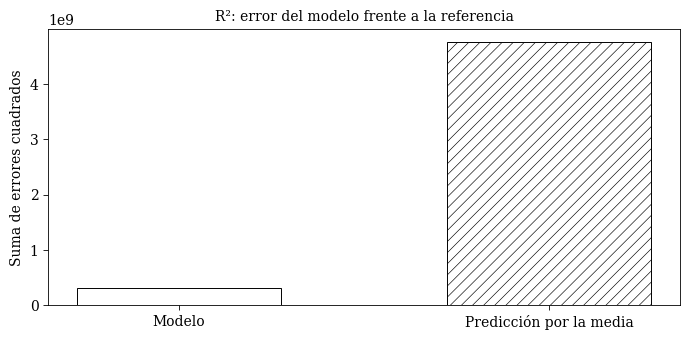

In [ ]:
from sklearn.metrics import r2_score

# Compara el modelo con una predicción basada en la media.
sse_modelo = ((y_test.to_numpy() - pred) ** 2).sum()
sst_media = ((y_test - y_test.mean()) ** 2).sum()
r2 = r2_score(y_test, pred)
rmse_media = (sst_media / len(y_test)) ** 0.5
r_pearson = X_test["YearsExperience"].corr(y_test)

print(f"R? del modelo: {r2:.3f}")
print(f"Correlaci?n r de Pearson en test: {r_pearson:.3f}")
print(f"SSE del modelo: {sse_modelo:,.0f}")
print(f"SST de referencia de la media: {sst_media:,.0f}")
print(f"RMSE del modelo: {rmse:,.0f} | RMSE de la referencia: {rmse_media:,.0f}")

plt.figure(figsize=(7, 3.5))
barras = plt.bar(
    ["Modelo", "predicción por la media"],
    [sse_modelo, sst_media],
    width=0.55,
    facecolor="white",
    edgecolor="black",
    linewidth=0.7,
)
barras[1].set_hatch("///")
plt.ylabel("Suma de errores cuadrados")
plt.title("R?: error del modelo frente a la referencia")
plt.tight_layout()
plt.show()

## 9. Residuos: ¿dónde se equivoca el modelo?

Un **residuo** es `salario real − salario predicho`: valores positivos indican subestimación y negativos, sobreestimación. La línea en cero representa una predicción exacta.

La última prueba suma 20 000 a **una sola predicción** para observar qué métricas reaccionan más, sin modificar los datos ni volver a entrenar.


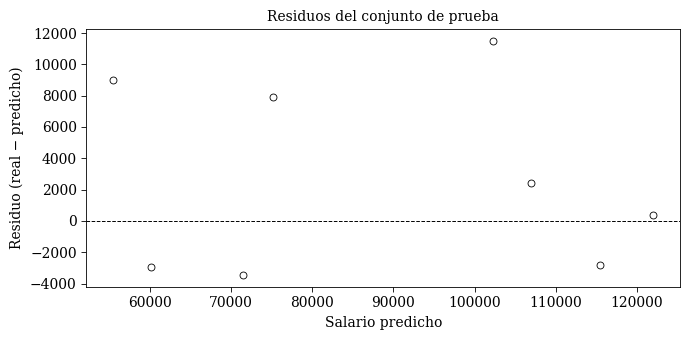

MAE:  5057.0 → 7557.0
RMSE: 6229.17 → 10140.36
R²:   0.935 → 0.827


In [ ]:
# Calcula los residuos como error de cada predicción.
residuos = y_test.to_numpy() - pred

plt.figure(figsize=(7, 3.5))
plt.scatter(
    pred,
    residuos,
    s=25,
    facecolors="white",
    edgecolors="black",
    linewidths=0.6,
)
plt.axhline(0, color="black", linewidth=0.7, linestyle="--")
plt.xlabel("Salario predicho")
plt.ylabel("Residuo (real ? predicho)")
plt.title("Residuos del conjunto de prueba")
plt.tight_layout()
plt.show()

# Introduce un error extremo en una sola predicción.
pred_extremo = pred.copy()
pred_extremo[0] += 20000

print(
    "MAE: ",
    round(mae, 2),
    "?",
    round(mean_absolute_error(y_test, pred_extremo), 2),
)
print(
    "RMSE:",
    round(rmse, 2),
    "?",
    round(mean_squared_error(y_test, pred_extremo) ** 0.5, 2),
)
print(
    "R?:  ",
    round(r2, 3),
    "?",
    round(r2_score(y_test, pred_extremo), 3),
)